# **E2 - Neural Networks with PyTorch**

## **A) Tensors**

**PyTorch:**
- [Local Installation](https://pytorch.org/get-started/locally/)
- Open-source deep learning framework developed by Meta.
- Primarily used for training and running neural networks
- GPU support for faster training and inference
- Advantages: usability and flexibility through dynamic computational graph system

**Dynamic computational graph system (Define-by-run):**
- Computational graph tracks operations and tensors so that gradients can be automatically computed via backpropagation.
- Static Graph (Define-then-Run): Graph is compiled once before execution. → Fast but less flexible
- Dynamic Graph (Define-by-Run): Graph is built "on the fly" as operations are running
- Additional information: [Jain, 2024](https://medium.com/@abhishekjainindore24/static-vs-dynamic-computational-graphs-5a49d1e3030b)

### Task 0: Make sure you have PyTorch correctly installed

In [1]:
# Import libraries
import torch
import numpy as np
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import sklearn

In [2]:
print(torch.__version__)

2.9.0+cu126


**Questions:**
1. Who has already used PyTorch or some similar deep learning framework?
2. Test if PyTorch and other requirements are successfully installed.

### Task 1: Create Tensors

[Fathah KA, 2022](https://medium.com/@fathahka/scalar-vector-matrix-tensor-in-linear-algr-f1bc673fa4eb)
![Tensor](https://miro.medium.com/v2/resize:fit:1100/format:webp/1*OaUbgSxKnC_kaRj0H6vK5Q.jpeg)

**Tensors:**
- Tensors are a specialized data structure that are very similar to arrays and matrices.
- In PyTorch, we use tensors to encode the inputs and outputs of a model, as well as the model’s parameters.
- Tensors are similar to NumPy’s ndarrays, except that tensors can run on GPUs or other hardware accelerators.

In [5]:
# Initialize Tensors
# from data:
data = [[5, 1, 7, 9],[4, 12, 19, 0]]
x_data = torch.tensor(data)

# from a numpy array:
np_array = np.array(data)
x_np = torch.from_numpy(np_array)

# from another tensor:
x_ones = torch.ones_like(x_data) # retains the properties of x_data
x_rand = torch.rand_like(x_data, dtype=torch.float) # overrides the datatype of x_data

# with random or constant values:
shape = (4,3,)    # shape is a tuple of tensor dimensions
rand_tensor = torch.rand(shape)
ones_tensor = torch.ones(shape)
zeros_tensor = torch.zeros(shape)

**Questions:**
1. Print all tensors to explore different initialization possibilities.
2. What are the attributes of a tensor? *(Hint: print the shape and the data type of one of the tensors)*

**Solution**

In [ ]:
######################
#    Solution Q1     #
######################


In [ ]:
######################
#    Solution Q2     #
######################


Additional attribute of each tensor is the device on which it is stored.

In [ ]:
print(f"Tensor is stored on: {rand_tensor.device}")

In [ ]:
# There are two ways to specify the device of the tensor
# You can switch the device of an already existing tensor by using the .to("[cpu|cuda]") command
if torch.cuda.is_available():
    rand_tensor = rand_tensor.to("cuda")
    print(f"Tensor is stored now on: {rand_tensor.device}")

# Or specify the device while creating the tensor
if torch.cuda.is_available():
    gpu_tensor = torch.tensor([3,4], device="cuda")
    print(f"New tensor is stored on: {gpu_tensor.device}")

### Task 2: Operations on Tensors

In [7]:
# Indexing and Slicing
rand_tensor = torch.rand(5,5)
print(rand_tensor)

tensor([[0.3678, 0.1563, 0.9936, 0.8531, 0.6914],
        [0.4923, 0.3763, 0.4244, 0.8558, 0.3710],
        [0.0969, 0.1379, 0.7170, 0.5161, 0.6668],
        [0.3191, 0.8351, 0.9645, 0.2398, 0.3287],
        [0.3607, 0.0491, 0.3949, 0.4124, 0.6190]])


In [9]:
# Joining tensors
tensor_a = torch.tensor([[1, 2, 3], [4, 5, 6]])
tensor_b = torch.tensor([[7, 8, 9], [10, 11, 12]])

# You can join tensors with torch.cat
join_cat = torch.cat((tensor_a, tensor_b), dim=0)
# or with torch.stack
join_stack = torch.stack((tensor_a, tensor_b), dim=0)

print(f"Concatenated tensor: \n {join_cat} \n")
print(f"Stacked tensor: \n {join_stack} \n")

Concatenated tensor: 
 tensor([[ 1,  2,  3],
        [ 4,  5,  6],
        [ 7,  8,  9],
        [10, 11, 12]]) 

Stacked tensor: 
 tensor([[[ 1,  2,  3],
         [ 4,  5,  6]],

        [[ 7,  8,  9],
         [10, 11, 12]]]) 



**Questions:**
1. Print first row or column of rand_tensor. Print last row or column. Change every value in middle column to be equal to 0.
2. What is the difference between torch.cat and torch.stack?

**Additional Content**

In [ ]:
# Arithmetic operations

tensor = torch.rand(3,4)
tensor_trans = tensor.T
print(f"Tensor: \n {tensor} \n")
print(f"Transpose tensor: \n {tensor_trans} \n")

# Matrix multiplication between two tensors
product1 = tensor @ tensor_trans
print(f"Product 1: \n {product1} \n")
product2 = tensor.matmul(tensor_trans)
print(f"Product 2: \n {product2} \n")
product3 = torch.rand_like(product1)
torch.matmul(tensor, tensor_trans, out=product3)

# Element-wise product
el_product1 = tensor * tensor
print(f"Element product 1: \n {el_product1} \n")
el_product2 = tensor.mul(tensor)
print(f"Element product 2: \n {el_product2} \n")
el_product3 = torch.rand_like(tensor)
torch.mul(tensor, tensor, out=el_product3)

## **B) Single Perceptrons**

Let's create a sample dataset for binary classification of email data with two features (e.g. length of the subject line and number of suspicious words)

**Features:** [length of subject, number of suspicious words]

**Labels:** 
- 1 for spam
- -1 for not spam

In [11]:
np.random.seed(42) # Seed for reproducibility

emails = np.array([
    [50, 10],
    [10, 2],
    [70, 12], 
    [5, 1],
    [40, 8],
    [8, 0],
    [20, 1],
    [30, 0],
    [20, 10],
])

labels = np.array([1, -1, 1, -1, 1, -1, -1, -1, 1])

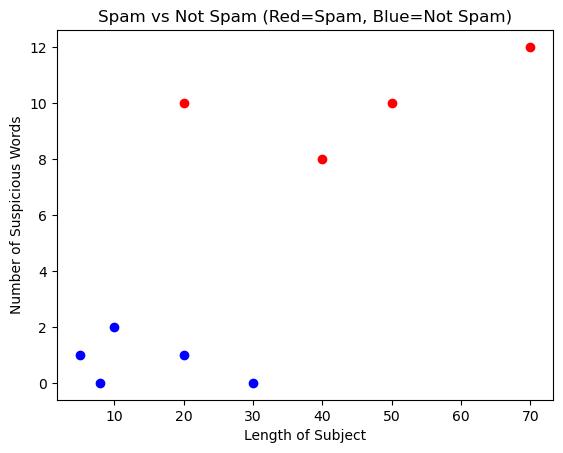

In [13]:
# Visualize the data
for email, label in zip(emails, labels):
    color = 'red' if label == 1 else 'blue'
    plt.scatter(email[0], email[1], color=color)
plt.xlabel('Length of Subject')
plt.ylabel('Number of Suspicious Words')
plt.title('Spam vs Not Spam (Red=Spam, Blue=Not Spam)')
plt.show()

### Task 3: Create Single Perceptron Algorithm

In [ ]:
class Perceptron:
    def __init__(self, learning_rate=0.1):
        self.learning_rate = learning_rate
        self.weights = None
        self.bias = None

    def fit(self, X, y):
        # Initialize weights and bias to zero
        n_samples, n_features = X.shape
        self.weights = np.zeros(n_features)
        self.bias = 0
        
        ###################################################
        #  Write Single Perceptron Algorithm
    
    def predict(self, X):
        linear_output = np.dot(X, self.weights) + self.bias
        return np.sign(linear_output)

In [ ]:
p = Perceptron(learning_rate=0.1)
p.fit(emails, labels)

# Make predictions
predictions = p.predict(emails)
print("Predictions:", predictions)
print("True labels:", labels)

# Check the accuracy
accuracy = np.mean(predictions == labels)
print(f"Accuracy: {accuracy * 100}%")

**Questions:**
    
1. Complete the algorithm for the Single Perceptron to train it, predict the spam-mail classification, and evaluate the accuracy. *(Hint: look in the lecture for the pseudo-code)*
2. What will happen if the data is not linearly separable? (*Hint: if errors == 0*) How can we solve that?

## **C) Neural Networks**

### Task 4: Loading Dataset

Download the *Breast Cancer Wisconsin* dataset from Opal or [Wolberg, 1995](https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic) and save it to the same folder as the jupyter notebook.

**Attributes:** ID, diagnosis, 30 real-valued input features. The diagnosis can be M = malignant or B = benign.
- ignore column 1 = ID
- set the target to column 2 = diagnosis

In [15]:
#Load the dataset
dataset = np.loadtxt('wdbc.data', delimiter=',', dtype=str) # Change name to path of the file, if needed
print(dataset[:3])

X = dataset[:, 2:].astype(np.float32)
y = dataset[:, 1]
y = np.where(y == 'M', 1, 0).astype(np.float32) # Convert diagnosis (M/B) to numerical labels (e.g., M -> 1, B -> 0)

X = torch.tensor(X, dtype=torch.float32)
y = torch.tensor(y, dtype=torch.float32).reshape(-1, 1)

print(X[:3])
print(y[:3])

[['842302' 'M' '17.99' '10.38' '122.8' '1001' '0.1184' '0.2776' '0.3001'
  '0.1471' '0.2419' '0.07871' '1.095' '0.9053' '8.589' '153.4' '0.006399'
  '0.04904' '0.05373' '0.01587' '0.03003' '0.006193' '25.38' '17.33'
  '184.6' '2019' '0.1622' '0.6656' '0.7119' '0.2654' '0.4601' '0.1189']
 ['842517' 'M' '20.57' '17.77' '132.9' '1326' '0.08474' '0.07864'
  '0.0869' '0.07017' '0.1812' '0.05667' '0.5435' '0.7339' '3.398' '74.08'
  '0.005225' '0.01308' '0.0186' '0.0134' '0.01389' '0.003532' '24.99'
  '23.41' '158.8' '1956' '0.1238' '0.1866' '0.2416' '0.186' '0.275'
  '0.08902']
 ['84300903' 'M' '19.69' '21.25' '130' '1203' '0.1096' '0.1599' '0.1974'
  '0.1279' '0.2069' '0.05999' '0.7456' '0.7869' '4.585' '94.03' '0.00615'
  '0.04006' '0.03832' '0.02058' '0.0225' '0.004571' '23.57' '25.53'
  '152.5' '1709' '0.1444' '0.4245' '0.4504' '0.243' '0.3613' '0.08758']]
tensor([[1.7990e+01, 1.0380e+01, 1.2280e+02, 1.0010e+03, 1.1840e-01, 2.7760e-01,
         3.0010e-01, 1.4710e-01, 2.4190e-01, 7.8710e

### Task 5: Build A Multilayer Perceptron Model

**Network Model Overview**

- The network model consists of a few layers of fully connected perceptrons.
- In our usecase:
  - The dataset contains 12 input features (predictors).
  - The output is a single binary value (0 or 1).
- Therefore:
  - The first layer should accept 12 inputs.
  - The final layer should produce 1 output.
- The architecture includes 3 fully connected layers.
- Each layer is created in PyTorch using the syntax:  
  `nn.Linear(x, y)`  
  - `x` is the number of inputs to the layer.  
  - `y` is the number of outputs from the layer.
- A **ReLU (Rectified Linear Unit)** activation function is applied between each layer.
- At the output layer, a **Sigmoid activation function** is used to ensure the final output is between 0 and 1.
- This is a typical neural network structure. A deep learning model usually contains many such layers stacked together.

In [17]:
model = nn.Sequential(
    nn.Linear(30, 12),  # 30 input features, 12 hidden units
    nn.ReLU(),
    nn.Linear(12, 8),   # 12 input to 8 hidden units
    nn.ReLU(), 
    nn.Linear(8, 1),    # 8 input units to 1 output (binary classification)
    nn.Sigmoid()
)
print(model)

Sequential(
  (0): Linear(in_features=30, out_features=12, bias=True)
  (1): ReLU()
  (2): Linear(in_features=12, out_features=8, bias=True)
  (3): ReLU()
  (4): Linear(in_features=8, out_features=1, bias=True)
  (5): Sigmoid()
)


**Questions:**
1. Try to add another layer that outputs 20 values after the first Linear layer above. What should you change?

**Solution**

In [ ]:
######################
#    Solution Q1     #
######################


### Task 6: Train a PyTorch Model

**Training a Neural Network in PyTorch**

Building a neural network in PyTorch does not tell how you should train the model for a particular job. In fact, there are many variations in this aspect as described by the hyperparameters. In PyTorch, or all deep learning models in general, you need to decide the following on how to train a model:

- What is the dataset, specifically how the input and target looks like
- What is the loss function to evaluate the goodness of fit of the model to the data
- What is the optimization algorithm to train the model, and the parameters to the optimization algorithm such as learning rate and number of iterations to train

Since it is a binary classification problem, the loss function should be **binary cross entropy**. It means that the target of the model output is 0 or 1 for the classification result. But in reality the model may output anything in between. The closer it is to the target value, the better (i.e., lower loss).

Gradient descent is the algorithm to optimize neural networks. There are many variations of gradient descent and **Adam** is one of the most used.

The training process described above can be implemented using the following code:

In [19]:
model = nn.Sequential(
    nn.Linear(30, 12),  # 30 input features, 12 hidden units
    nn.ReLU(),
    nn.Linear(12, 8),   # 12 input to 8 hidden units
    nn.ReLU(), 
    nn.Linear(8, 1),    # 8 input units to 1 output (binary classification)
    nn.Sigmoid()
)

loss_fn = nn.BCELoss() # binary cross-entropy
optimizer = optim.Adam(model.parameters(), lr=0.001)

def train_model(n_epochs, batch_size=None):
    losses = []
    for epoch in range(n_epochs):
        epoch_loss = 0.0
        for i in range(0, len(X), batch_size if batch_size else len(X)):
            Xbatch = X[i:i + (batch_size if batch_size else len(X))]
            ybatch = y[i:i + (batch_size if batch_size else len(X))]
            
            # Forward pass
            y_pred = model(Xbatch)
            loss = loss_fn(y_pred, ybatch)
            
            # Backward pass and optimization
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            
            epoch_loss += loss.item()
        avg_loss = epoch_loss / len(X)
        losses.append(avg_loss)
    
    return losses

- The for-loop above retrieves a batch of data and feeds it into the model.
- The model’s output is then compared to the target to calculate the loss.
- Based on this loss, the optimizer updates the model’s parameters in one step to improve its fit to the training data.
- After many such updates, the model should approximate the training data closely enough to predict the target with high accuracy.

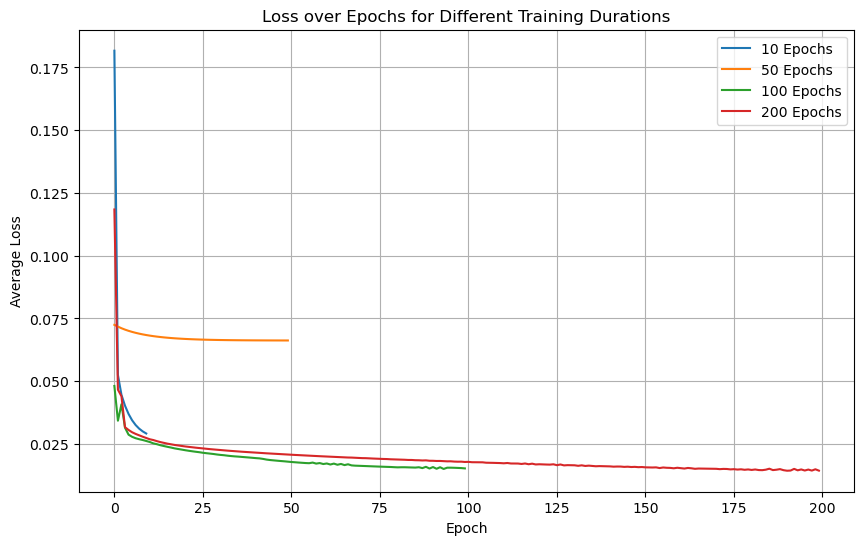

In [21]:
epoch_list = [10, 50, 100, 200]  # TODO Test different epochs
batch_size = 10  # TODO Test different batch sizes

# Initialize a dictionary to store the loss results for each epoch setting
loss_results = {}

# Loop through different epoch values and train the model
for epochs in epoch_list:
    model.apply(lambda m: m.reset_parameters() if hasattr(m, 'reset_parameters') else None)  # Reset model weights
    loss_results[epochs] = train_model(epochs, batch_size)

# Plot the losses for each epoch setting
plt.figure(figsize=(10, 6))
for epochs in epoch_list:
    plt.plot(loss_results[epochs], label=f'{epochs} Epochs')

# Add labels and titles
plt.title('Loss over Epochs for Different Training Durations')
plt.xlabel('Epoch')
plt.ylabel('Average Loss')
plt.legend()
plt.grid(True)

# Show the plot
plt.show()

*Experiment with different values for the number of epochs and the batch size*

**Questions:**
1. How does the loss change with different number of epochs *(e.g., 10, 50, 100, 200)*
2. What is the influence of the batch size? What happens if you remove it?

### Task 7: Test the Model

Some models behave differently during training and inference.

In [ ]:
i = 5
X_sample = X[i:i+1]
model.eval()    # signal the model that the intention is to run the model for inference
with torch.no_grad():    # create context for the model, that running the gradient is not required --> consumes less resources
    y_pred = model(X_sample)
print(f"{X_sample[0]} -> {y_pred[0]}")

- **Evaluating the model:**
  - The model outputs a sigmoid value, which is between 0 and 1.
  - You can interpret this value by rounding it to the nearest integer (i.e., converting it to a Boolean label).
  - By comparing how often the rounded predictions match the target, you can calculate the model's accuracy percentage as follows:

In [ ]:
with torch.no_grad():
    y_pred = model(X)
accuracy = (y_pred.round() == y).float().mean()
print(f"Accuracy {accuracy}")

**Questions:**
1. What is your accuracy?
2. Does it change if you change the number of epochs during the training?

### Task 8: Overfitting

Let's observe the problem of overfitting and some possible solutions!

First, we can split the dataset into training and validation dataset to explore in detail.

In [23]:
from sklearn.model_selection import train_test_split
import warnings

warnings.filterwarnings("ignore", category=UserWarning)

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)
X_train = torch.tensor(X_train, dtype=torch.float32)
X_val = torch.tensor(X_val, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.float32).reshape(-1, 1)
y_val = torch.tensor(y_val, dtype=torch.float32).reshape(-1, 1)

In [25]:
model = nn.Sequential(
    nn.Linear(30, 12),  # 30 input features, 12 hidden units
    nn.ReLU(),
    nn.Linear(12, 8),   # 12 input to 8 hidden units
    nn.ReLU(), 
    nn.Linear(8, 1),    # 8 input units to 1 output (binary classification)
    nn.Sigmoid()
)

loss_fn = nn.BCELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

n_epochs = 1000
train_losses = []
val_losses = []

for epoch in range(n_epochs):
    model.train()
    for i in range(0, len(X_train), batch_size):
        Xbatch = X_train[i:i+batch_size]
        ybatch = y_train[i:i+batch_size]
        y_pred = model(Xbatch)
        loss = loss_fn(y_pred, ybatch)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    
    # Record the training loss
    with torch.no_grad():
        y_pred_train = model(X_train)
        train_loss = loss_fn(y_pred_train, y_train).item()
        train_losses.append(train_loss)
    
    # Validation phase
    model.eval()
    with torch.no_grad():
        y_pred_val = model(X_val)
        val_loss = loss_fn(y_pred_val, y_val).item()
        val_losses.append(val_loss)
    
    if epoch % 50 == 0:  # Monitor every 50 epochs
        print(f"Epoch {epoch} | Train Loss: {loss.item():.4f} | Val Loss: {val_loss:.4f}")

Epoch 0 | Train Loss: 0.8046 | Val Loss: 0.6847
Epoch 50 | Train Loss: 0.0462 | Val Loss: 0.0959
Epoch 100 | Train Loss: 0.0258 | Val Loss: 0.0791
Epoch 150 | Train Loss: 0.0168 | Val Loss: 0.0745
Epoch 200 | Train Loss: 0.0097 | Val Loss: 0.0765
Epoch 250 | Train Loss: 0.0092 | Val Loss: 0.0695
Epoch 300 | Train Loss: 0.0080 | Val Loss: 0.0671
Epoch 350 | Train Loss: 0.0073 | Val Loss: 0.0652
Epoch 400 | Train Loss: 0.0065 | Val Loss: 0.0642
Epoch 450 | Train Loss: 0.0053 | Val Loss: 0.0640
Epoch 500 | Train Loss: 0.0047 | Val Loss: 0.0638
Epoch 550 | Train Loss: 0.0044 | Val Loss: 0.0636
Epoch 600 | Train Loss: 0.0038 | Val Loss: 0.0619
Epoch 650 | Train Loss: 0.0036 | Val Loss: 0.0603
Epoch 700 | Train Loss: 0.0032 | Val Loss: 0.0594
Epoch 750 | Train Loss: 0.0029 | Val Loss: 0.0587
Epoch 800 | Train Loss: 0.0026 | Val Loss: 0.0581
Epoch 850 | Train Loss: 0.0026 | Val Loss: 0.0566
Epoch 900 | Train Loss: 0.0028 | Val Loss: 0.0614
Epoch 950 | Train Loss: 0.0025 | Val Loss: 0.0597


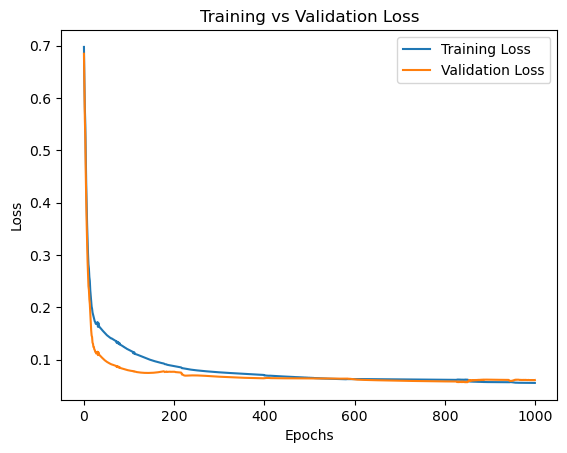

In [27]:
# Visualizing Training Loss and Validation Loss

plt.plot(train_losses, label='Training Loss')
plt.plot(val_losses, label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.title('Training vs Validation Loss')
plt.show()

**Questions:**
1. Train a model with a high number of epochs e.g. > 1000.
2. Do you observe Overfitting? How do the training loss, the validation loss and accuracy change?
3. How can you handle Overfitting?